# Linear-model theory: consistent 2 × 2 and 1 × 4 figures

Reproduction of Figure `fig:ls-limit` in `JRSSB_revision.tex`, from
`linear_model_theory/linear_model_limit_figure.py` and its unchanged solver.
Run all cells from the repository root. Requires NumPy, SciPy, Matplotlib, and a
working LaTeX installation (the same requirements as the consistent M1–M3 plots).

**Only presentation changes:** residual profiles occupy the top row; Hausdorff-error
heatmaps occupy the bottom row. The numerical resolution, parameters, split-index
convention, curve colours, true/limiting change-point markers, heatmap mask,
extent, and shared viridis scale are preserved. No simulations are rerun.

The `PAPER_STYLE` dictionary below is copied from **Updated consistent plots** in
`M1_upsample_final.ipynb` (also shared by M2/M3). This is their compact diagnostic
style, with Computer Modern via LaTeX, 10.5 pt labels/titles and 8.5 pt ticks.
The fixed canvas matches the paper's text width, so inclusion at `\\textwidth`
preserves those sizes. PDF and PNG exports go to `figures/linear_model_theory/`.
The notebook never writes to the paper repository.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from linear_model_theory.linear_model_theory_lib import solve, split

ROOT = Path.cwd()
assert (ROOT / 'linear_model_theory/linear_model_limit_figure.py').is_file(), 'Run from the repository root.'
OUT = ROOT / 'figures/linear_model_theory'
OUT.mkdir(parents=True, exist_ok=True)
SOURCE_PATHS = [ROOT / 'linear_model_theory' / name for name in
                ('linear_model_limit_figure.py', 'linear_model_theory_lib.py')]
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in SOURCE_PATHS}
PAPER_WIDTH = 427.64493 / 72.27

PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}
plt.rcParams.update(PAPER_STYLE)


## Original calculation

Keep the original midpoint grid (`N = 1500`), 37-point change-point grid,
minimum grid separation (`0.049`), and `(split(v) - 1) / N` convention.
The two heatmaps use the original common range `[0, 0.6]`; invalid change-point
pairs remain masked. All computations use the original `solve` and `split`.


In [2]:
N = 1500
t = (np.arange(N) + 0.5) / N

L = 3
Phi = np.array([(1-t)**2, 2*t*(1-t), t**2])
delta = 4
rho = 0.5
Gam = np.array([[1, rho, rho**2], [rho, 1, rho], [rho**2, rho, 1]])

def lim(a1, a2, sigma):
    Psi = np.where(t < a1, 0, np.where(t < a2, 1, 2))
    b, Lam, K, v = solve(Phi, Psi, delta, Gam, sigma)
    return v, (split(v) - 1) / N

def dH(A, B):
    return max(max(min(abs(x-y) for y in B) for x in A),
               max(min(abs(x-y) for x in A) for y in B))

configurations = [(0.4, 0.7), (0.1, 0.3)]
profiles = [lim(a1, a2, 1.0) for a1, a2 in configurations]
g = np.linspace(0.05, 0.95, 37)
sigmas = [1.0, 0.3]
heatmaps = []
for sigma in sigmas:
    H = np.full((len(g), len(g)), np.nan)
    for i, a1 in enumerate(g):
        for j, a2 in enumerate(g):
            if a2 - a1 >= 0.049:
                H[j, i] = dH((a1, a2), lim(a1, a2, sigma)[1])
    heatmaps.append(H)
for alpha, (_, tau) in zip(configurations, profiles):
    print(f'alpha = {alpha}: tau* = {tau}')


alpha = (0.4, 0.7): tau* = [0.4   0.686]
alpha = (0.1, 0.3): tau* = [0.3        0.64866667]


## Updated consistent plots

Read the panels in row-major order, as in the original left-to-right order.
Each top panel retains its three-curve legend. Black dashed lines mark the true
change points and red dotted lines mark the limiting estimates. The bottom row
shares one colour bar. Colours and line styles retain their original meanings.


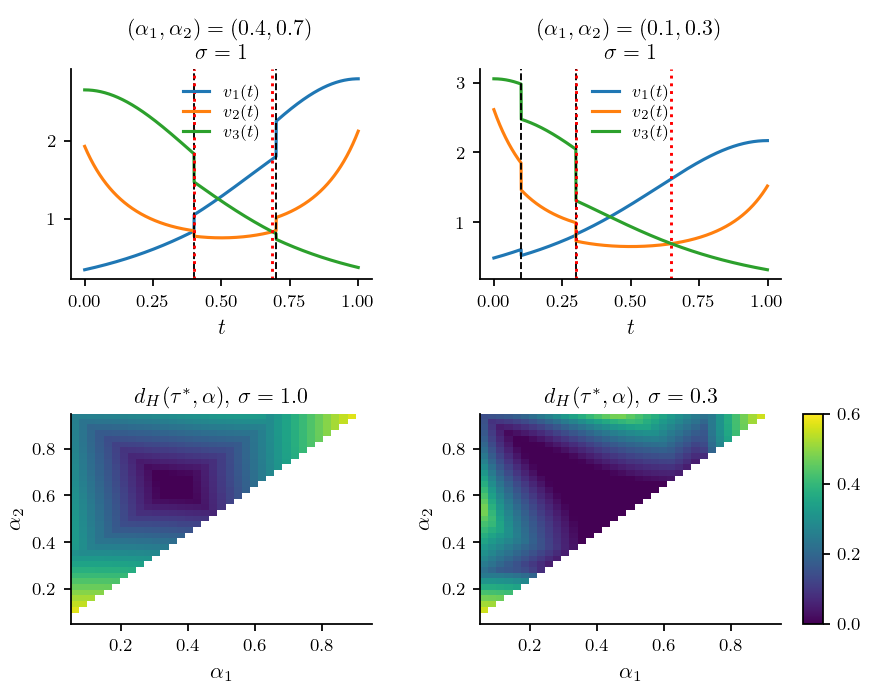

In [3]:
with plt.rc_context(PAPER_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(PAPER_WIDTH, 4.65))
    fig.subplots_adjust(left=0.08, right=0.88, bottom=0.105, top=0.90,
                        wspace=0.36, hspace=0.64)
    for k, ((a1, a2), (v, tau)) in enumerate(zip(configurations, profiles)):
        ax = axes[0, k]
        for ell in range(L):
            ax.plot(t, v[:, ell], color=['#1f77b4', '#ff7f0e', '#2ca02c'][ell],
                    linewidth=1.5, label=fr'$v_{ell+1}(t)$')
        for a in (a1, a2):
            ax.axvline(a, color='k', ls='--', lw=0.9)
        for s in tau:
            ax.axvline(s, color='r', ls=':', lw=1.4)
        ax.set_xlabel('$t$')
        ax.set_title(fr'$(\alpha_1,\alpha_2)=({a1},{a2})$' + '\n' + r'$\sigma=1$', pad=5)
        ax.legend(loc='best', handlelength=1.6, labelspacing=0.2)
    for k, (sigma, H) in enumerate(zip(sigmas, heatmaps)):
        ax = axes[1, k]
        im = ax.imshow(H, origin='lower', extent=[g[0], g[-1], g[0], g[-1]],
                       cmap='viridis', aspect='auto', vmin=0, vmax=0.6,
                       interpolation='nearest')
        ax.set_xlabel(r'$\alpha_1$')
        ax.set_ylabel(r'$\alpha_2$')
        ax.set_title(fr'$d_H(\tau^*,\alpha)$, $\sigma={sigma}$', pad=5)
    bottom_box = axes[1, 1].get_position()
    cax = fig.add_axes([0.905, bottom_box.y0, 0.022, bottom_box.height])
    colorbar = fig.colorbar(im, cax=cax, ticks=np.linspace(0, 0.6, 4))
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax in fig.axes:
        box = ax.get_tightbbox(renderer)
        assert box.x0 >= 0 and box.y0 >= 0
        assert box.x1 <= fig.bbox.width and box.y1 <= fig.bbox.height
    for extension in ('pdf', 'png'):
        fig.savefig(OUT / f'linear_model_limit.{extension}', bbox_inches=None, dpi=300)
fig


## Verify against the original script

Execute the unmodified original script with its file writes suppressed, then
compare the data attached to all original plot artists. This checks every
profile sample, every true/estimated marker, both complete heatmaps (including
the mask), extents, and colour limits. This cell closes the figures after checking.


In [4]:
import runpy
import sys
from unittest.mock import patch

sys.path.insert(0, str(ROOT / 'linear_model_theory'))
try:
    with plt.rc_context(), patch.object(plt, 'savefig'):
        original = runpy.run_path(str(SOURCE_PATHS[0]))
finally:
    sys.path.pop(0)
for k in range(2):
    new_lines, old_lines = axes[0, k].lines, original['ax'][k].lines
    assert len(new_lines) == len(old_lines) == 7
    for new, old in zip(new_lines, old_lines):
        np.testing.assert_array_equal(new.get_xdata(), old.get_xdata())
        np.testing.assert_array_equal(new.get_ydata(), old.get_ydata())
for k in range(2):
    new = axes[1, k].images[0]
    old = original['ax'][k + 2].images[0]
    np.testing.assert_array_equal(np.ma.getmaskarray(new.get_array()),
                                  np.ma.getmaskarray(old.get_array()))
    np.testing.assert_array_equal(new.get_array().filled(np.nan),
                                  old.get_array().filled(np.nan))
    np.testing.assert_array_equal(new.get_extent(), old.get_extent())
    assert new.get_clim() == old.get_clim() == (0, 0.6)
    assert new.get_cmap().name == old.get_cmap().name == 'viridis'
    assert np.isfinite(heatmaps[k]).sum() == 630
assert source_hashes == {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                         for p in SOURCE_PATHS}
manifest = {
    'source_sha256': source_hashes,
    'style_reference': 'M1_upsample_final.ipynb: Updated consistent plots / PAPER_STYLE',
    'layout': '2x2; residual profiles above Hausdorff heatmaps',
    'size_inches': fig.get_size_inches().tolist(),
    'N': N, 'grid_points': len(g), 'valid_pairs_per_heatmap': 630,
    'tau_star': [tau.tolist() for _, tau in profiles],
    'original_artist_arrays_exactly_equal': True,
    'pdf_sha256': hashlib.sha256((OUT / 'linear_model_limit.pdf').read_bytes()).hexdigest(),
}
(OUT / 'reproduction.json').write_text(json.dumps(manifest, indent=2) + '\n')
plt.close(original['fig'])
plt.close(fig)
print('PASS: all curve/marker coordinates and both heatmaps exactly match the original script.')
print('PDF:', OUT / 'linear_model_limit.pdf')


(0.4, 0.7) [0.4   0.686]
(0.1, 0.3) [0.3        0.64866667]
PASS: all curve/marker coordinates and both heatmaps exactly match the original script.
PDF: /scratch/ga442/gab-code-env/papers/WeightedERM-reference/figures/linear_model_theory/linear_model_limit.pdf


## Alternative: compact, readable 1 × 4 layout

The original four panels retain their data, colours, line styles, and shared
colour scale. The 7.6 × 2.35 inch canvas has closer panels and larger type/strokes
for inclusion at the manuscript text width. At that width, axis labels are about
9.3 pt, ticks 7.8 pt, and the plotting area is taller than the initial wide export.
The Computer Modern/LaTeX styling matches the other consistent plots.
Run the setup/calculation cells above first. Files:
`figures/linear_model_theory/linear_model_limit_1x4.pdf` and `.png`.
Both layouts are included in the manuscript as separate figures, with author approval.

Only the second residual-profile panel carries the shared curve legend.

The gap between the curve and heatmap groups is wider; spacing within each pair is unchanged.


PASS: the 1 x 4 alternative preserves all profiles, markers and heatmap data.


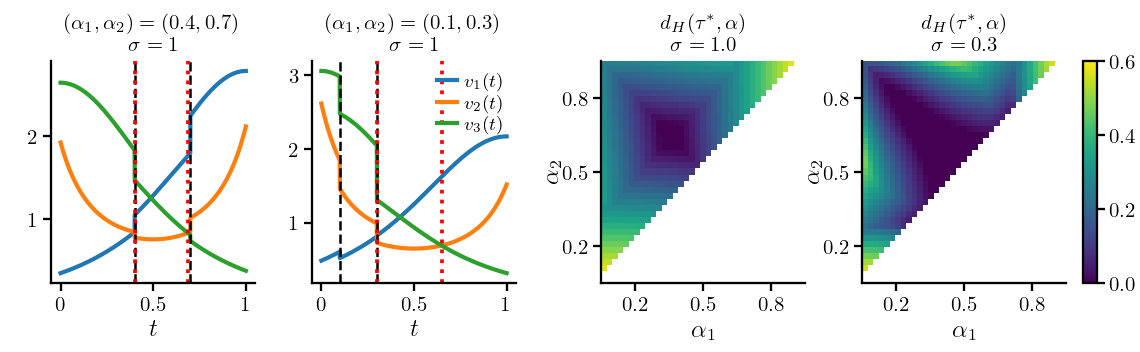

In [5]:
# Larger printed type/strokes with a narrower canvas and smaller panel gaps.
ROW_STYLE = {
    **PAPER_STYLE,
    'font.size': 10, 'axes.labelsize': 12, 'axes.titlesize': 10,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 9,
    'axes.linewidth': 1.1, 'xtick.major.width': 1.1, 'ytick.major.width': 1.1,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'xtick.major.pad': 2, 'ytick.major.pad': 2, 'axes.labelpad': 2,
}
with plt.rc_context(ROW_STYLE):
    fig_row, axes_row = plt.subplots(1, 4, figsize=(7.6, 2.35))
    fig_row.subplots_adjust(left=0.045, right=0.935, bottom=0.195, top=0.826,
                            wspace=0.27)
    # Keep each pair's gap fixed; add a small visual break between groups.
    group_gap_extra = 0.025  # fraction of the full figure width
    positions = [ax.get_position().frozen() for ax in axes_row]
    pair_gap = positions[1].x0 - positions[0].x1
    panel_width = positions[0].width - group_gap_extra / 4
    for k, ax in enumerate(axes_row):
        left = (positions[0].x0 + k * (panel_width + pair_gap)
                + (group_gap_extra if k >= 2 else 0))
        ax.set_position([left, positions[k].y0, panel_width, positions[k].height])
    for k, ((a1, a2), (v, tau)) in enumerate(zip(configurations, profiles)):
        ax = axes_row[k]
        for ell in range(L):
            ax.plot(t, v[:, ell], color=['#1f77b4', '#ff7f0e', '#2ca02c'][ell],
                    linewidth=2.0, label=fr'$v_{ell+1}(t)$')
        for a in (a1, a2):
            ax.axvline(a, color='k', ls='--', lw=1.2)
        for s in tau:
            ax.axvline(s, color='r', ls=':', lw=1.8)
        ax.set_xlabel('$t$')
        ax.set_xticks([0, 0.5, 1], labels=['0', '0.5', '1'])
        ax.set_yticks([1, 2] if k == 0 else [1, 2, 3])
        ax.set_title(fr'$(\alpha_1,\alpha_2)=({a1},{a2})$' + '\n' + r'$\sigma=1$', pad=5)
        if k == 1:
            ax.legend(loc='upper right', frameon=False, handlelength=1.1,
                      labelspacing=0.15, handletextpad=0.35, borderaxespad=0.25)
    for k, (sigma, H) in enumerate(zip(sigmas, heatmaps)):
        ax = axes_row[k + 2]
        im = ax.imshow(H, origin='lower', extent=[g[0], g[-1], g[0], g[-1]],
                       cmap='viridis', aspect='auto', vmin=0, vmax=0.6,
                       interpolation='nearest')
        ax.set_xlabel(r'$\alpha_1$')
        ax.set_ylabel(r'$\alpha_2$', labelpad=0)
        ax.set_xticks([0.2, 0.5, 0.8])
        ax.set_yticks([0.2, 0.5, 0.8])
        ax.set_title(r'$d_H(\tau^*,\alpha)$' + '\n' + fr'$\sigma={sigma}$', pad=5)
    bottom_box = axes_row[3].get_position()
    cax = fig_row.add_axes([0.950, bottom_box.y0, 0.012, bottom_box.height])
    colorbar = fig_row.colorbar(im, cax=cax, ticks=np.linspace(0, 0.6, 4))
    fig_row.canvas.draw()
    renderer = fig_row.canvas.get_renderer()
    for ax in fig_row.axes:
        box = ax.get_tightbbox(renderer)
        assert box.x0 >= 0 and box.y0 >= 0
        assert box.x1 <= fig_row.bbox.width and box.y1 <= fig_row.bbox.height
    for extension in ('pdf', 'png'):
        fig_row.savefig(OUT / f'linear_model_limit_1x4.{extension}', bbox_inches=None, dpi=300)
for k, (v, tau) in enumerate(profiles):
    for ell in range(L):
        np.testing.assert_array_equal(axes_row[k].lines[ell].get_xdata(), t)
        np.testing.assert_array_equal(axes_row[k].lines[ell].get_ydata(), v[:, ell])
    for line, location in zip(axes_row[k].lines[3:], [*configurations[k], *tau]):
        np.testing.assert_array_equal(line.get_xdata(), [location, location])
for k, H in enumerate(heatmaps):
    image = axes_row[k + 2].images[0]
    np.testing.assert_array_equal(image.get_array().filled(np.nan), H)
    np.testing.assert_array_equal(image.get_extent(), [g[0], g[-1], g[0], g[-1]])
    assert image.get_clim() == (0, 0.6)
    assert image.get_cmap().name == 'viridis'
print('PASS: the 1 x 4 alternative preserves all profiles, markers and heatmap data.')
plt.close(fig_row)
fig_row


## Manuscript handoff

Both layouts are included in `JRSSB_revision.tex`, with the author's approval:
- `fig:ls-limit`: `figures/linear_model/linear_model_limit.pdf` (2 × 2).
- `fig:ls-limit-1x4`: `figures/linear_model/linear_model_limit_1x4.pdf` (1 × 4).

Paths are relative to `JRSSB-revision-rebuttal/`. The 2 × 2 caption has green
“Top two” / “Bottom two” wording; the new comparison caption is highlighted in
green and describes the left/right pairs. Main-body prose is unchanged.
The notebook itself only exports figures and never edits the manuscript.
